# Lab 1: Базові алгоритми класифікації у Scikit-learn

Камінський Валентин, ФБ-61мн

Датасет: CTU-IoT-Malware-Capture-1-1 (IoT-23) - мережевий трафік IoT-пристрою, зараженого ботнетом Mirai.  
https://www.kaggle.com/datasets/agungpambudi/network-malware-detection-connection-analysis

Кожен рядок - одне мережеве з'єднання з логу Zeek (conn.log). Задача - бінарна класифікація: `Malicious` чи `Benign`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from sklearn import set_config
set_config(display="text")

## Get the Data

In [2]:
# роздільник '|', пропуски позначені '-'
df = pd.read_csv('CTU-IoT-Malware-Capture-1-1conn.log.labeled.csv', sep='|', na_values=['-'], low_memory=False)

In [3]:
df.shape

(1008748, 23)

In [4]:
df.head()

,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,...,local_resp,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,tunnel_parents,label,detailed-label
0,1.525880e+09,CUmrqr4svHuSXJy5z7,192.168.100.103,51524.0,65.127.233.163,23.0,tcp,NaN,2.999051,0.0,...,NaN,0.0,S,3.0,180.0,0.0,0.0,NaN,Malicious,PartOfAHorizontalPortScan
1,1.525880e+09,CH98aB3s1kJeq6SFOc,192.168.100.103,56305.0,63.150.16.171,23.0,tcp,NaN,NaN,NaN,...,NaN,0.0,S,1.0,60.0,0.0,0.0,NaN,Malicious,PartOfAHorizontalPortScan
2,1.525880e+09,C3GBTkINvXNjVGtN5,192.168.100.103,41101.0,111.40.23.49,23.0,tcp,NaN,NaN,NaN,...,NaN,0.0,S,1.0,60.0,0.0,0.0,NaN,Malicious,PartOfAHorizontalPortScan
3,1.525880e+09,CDe43c1PtgynajGI6,192.168.100.103,60905.0,131.174.215.147,23.0,tcp,NaN,2.998796,0.0,...,NaN,0.0,S,3.0,180.0,0.0,0.0,NaN,Malicious,PartOfAHorizontalPortScan
4,1.525880e+09,CJaDcG3MZzvf1YVYI4,192.168.100.103,44301.0,91.42.47.63,23.0,tcp,NaN,NaN,NaN,...,NaN,0.0,S,1.0,60.0,0.0,0.0,NaN,Malicious,PartOfAHorizontalPortScan


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1008748 entries, 0 to 1008747
Data columns (total 23 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   ts              1008748 non-null  float64
 1   uid             1008748 non-null  object 
 2   id.orig_h       1008748 non-null  object 
 3   id.orig_p       1008748 non-null  float64
 4   id.resp_h       1008748 non-null  object 
 5   id.resp_p       1008748 non-null  float64
 6   proto           1008748 non-null  object 
 7   service         3241 non-null     object 
 8   duration        212448 non-null   float64
 9   orig_bytes      212448 non-null   float64
 10  resp_bytes      212448 non-null   float64
 11  conn_state      1008748 non-null  object 
 12  local_orig      0 non-null        float64
 13  local_resp      0 non-null        float64
 14  missed_bytes    1008748 non-null  float64
 15  history         991327 non-null   object 
 16  orig_pkts       1008748 non-null  fl

In [6]:
df.describe()

,ts,id.orig_p,id.resp_p,duration,orig_bytes,resp_bytes,local_orig,local_resp,missed_bytes,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,tunnel_parents
count,1.008748e+06,1.008748e+06,1.008748e+06,212448.000000,212448.000000,212448.000000,0.0,0.0,1008748.0,1.008748e+06,1.008748e+06,1.008748e+06,1.008748e+06,0.0
mean,1.526075e+09,4.443684e+04,1.609771e+04,3.203882,4.754095,11.856228,NaN,NaN,0.0,1.496242e+00,8.114562e+01,1.424647e-01,9.049184e+00,NaN
std,1.157431e+05,9.660592e+03,1.956280e+04,4.218760,23.359269,98.337115,NaN,NaN,0.0,1.741176e+00,9.473090e+01,1.850414e+00,1.196776e+02,NaN
min,1.525880e+09,3.000000e+00,0.000000e+00,0.000002,0.000000,0.000000,NaN,NaN,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN
25%,1.525975e+09,4.373000e+04,2.300000e+01,2.998560,0.000000,0.000000,NaN,NaN,0.0,1.000000e+00,4.000000e+01,0.000000e+00,0.000000e+00,NaN
50%,1.526071e+09,4.376300e+04,8.080000e+03,2.998797,0.000000,0.000000,NaN,NaN,0.0,1.000000e+00,6.000000e+01,0.000000e+00,0.000000e+00,NaN
75%,1.526174e+09,4.881400e+04,2.818025e+04,2.999042,0.000000,0.000000,NaN,NaN,0.0,1.000000e+00,6.000000e+01,0.000000e+00,0.000000e+00,NaN
max,1.526283e+09,6.539400e+04,6.553500e+04,293.010157,2202.000000,8991.000000,NaN,NaN,0.0,6.000000e+01,2.990000e+03,7.500000e+01,9.415000e+03,NaN


In [7]:
df['label'].value_counts()

label
Malicious    539473
Benign       469275
Name: count, dtype: int64

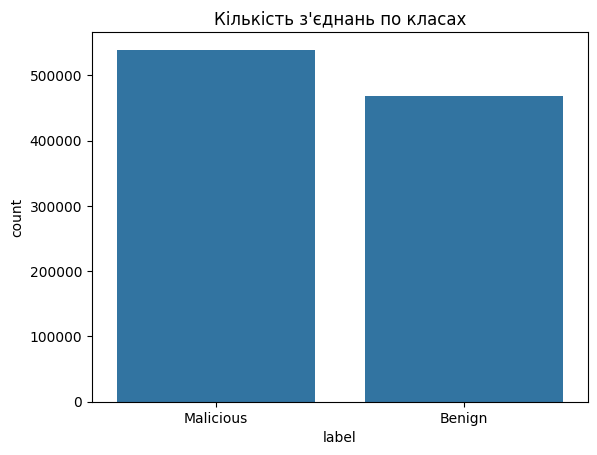

In [8]:
sns.countplot(x='label', data=df)
plt.title('Кількість з\'єднань по класах')
plt.show()

Класи майже збалансовані (~53% Malicious, ~47% Benign).

In [9]:
df['detailed-label'].value_counts()

detailed-label
PartOfAHorizontalPortScan    539465
C&C                               8
Name: count, dtype: int64

`detailed-label` - це уточнення мітки (тип атаки), тому його потрібно видалити, інакше модель фактично бачитиме відповідь.

## Data Preprocessing

In [10]:
df.isnull().sum()

ts                      0
uid                     0
id.orig_h               0
id.orig_p               0
id.resp_h               0
id.resp_p               0
proto                   0
service           1005507
duration           796300
orig_bytes         796300
resp_bytes         796300
conn_state              0
local_orig        1008748
local_resp        1008748
missed_bytes            0
history             17421
orig_pkts               0
orig_ip_bytes           0
resp_pkts               0
resp_ip_bytes           0
tunnel_parents    1008748
label                   0
detailed-label     469275
dtype: int64

`local_orig`, `local_resp`, `tunnel_parents` повністю порожні - видаляємо.  
Також видаляємо `ts`, `uid` та IP-адреси - це ідентифікатори, вони не допоможуть моделі на нових даних.

In [11]:
df = df.drop(['ts', 'uid', 'id.orig_h', 'id.resp_h', 'local_orig', 'local_resp',
              'tunnel_parents', 'detailed-label'], axis=1)

`duration`, `orig_bytes`, `resp_bytes` порожні приблизно в 79% рядків. В Zeek `-` у цих полях означає, що з'єднання не встановилось і даних не передавалось, тому заповнюємо 0 (а не середнім).

In [12]:
df['duration'] = df['duration'].fillna(0)
df['orig_bytes'] = df['orig_bytes'].fillna(0)
df['resp_bytes'] = df['resp_bytes'].fillna(0)

In [13]:
# для категоріальних пропуск робимо окремою категорією
df['service'] = df['service'].fillna('none')
df['history'] = df['history'].fillna('none')

In [14]:
df.isnull().sum().sum()

np.int64(0)

In [15]:
print(df['proto'].unique())
print(df['conn_state'].unique())
print(df['history'].nunique())

['tcp' 'udp' 'icmp']
['S0' 'REJ' 'SF' 'OTH' 'RSTOS0' 'RSTR' 'S2' 'RSTRH' 'RSTO' 'S1' 'SH']
126


Категоріальні ознаки (`proto`, `service`, `conn_state`, `history`) переводимо в числа через LabelEncoder. Ціль: Malicious -> 1, Benign -> 0.

In [16]:
for col in ['proto', 'service', 'conn_state', 'history']:
    df[col] = LabelEncoder().fit_transform(df[col])

df['label'] = (df['label'] == 'Malicious').astype(int)

In [17]:
df.head()

,id.orig_p,id.resp_p,proto,service,duration,orig_bytes,resp_bytes,conn_state,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label
0,51524.0,23.0,1,3,2.999051,0.0,0.0,6,0.0,21,3.0,180.0,0.0,0.0,1
1,56305.0,23.0,1,3,0.000000,0.0,0.0,6,0.0,21,1.0,60.0,0.0,0.0,1
2,41101.0,23.0,1,3,0.000000,0.0,0.0,6,0.0,21,1.0,60.0,0.0,0.0,1
3,60905.0,23.0,1,3,2.998796,0.0,0.0,6,0.0,21,3.0,180.0,0.0,0.0,1
4,44301.0,23.0,1,3,0.000000,0.0,0.0,6,0.0,21,1.0,60.0,0.0,0.0,1


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1008748 entries, 0 to 1008747
Data columns (total 15 columns):
 #   Column         Non-Null Count    Dtype  
---  ------         --------------    -----  
 0   id.orig_p      1008748 non-null  float64
 1   id.resp_p      1008748 non-null  float64
 2   proto          1008748 non-null  int64  
 3   service        1008748 non-null  int64  
 4   duration       1008748 non-null  float64
 5   orig_bytes     1008748 non-null  float64
 6   resp_bytes     1008748 non-null  float64
 7   conn_state     1008748 non-null  int64  
 8   missed_bytes   1008748 non-null  float64
 9   history        1008748 non-null  int64  
 10  orig_pkts      1008748 non-null  float64
 11  orig_ip_bytes  1008748 non-null  float64
 12  resp_pkts      1008748 non-null  float64
 13  resp_ip_bytes  1008748 non-null  float64
 14  label          1008748 non-null  int64  
dtypes: float64(10), int64(5)
memory usage: 115.4 MB


## EDA

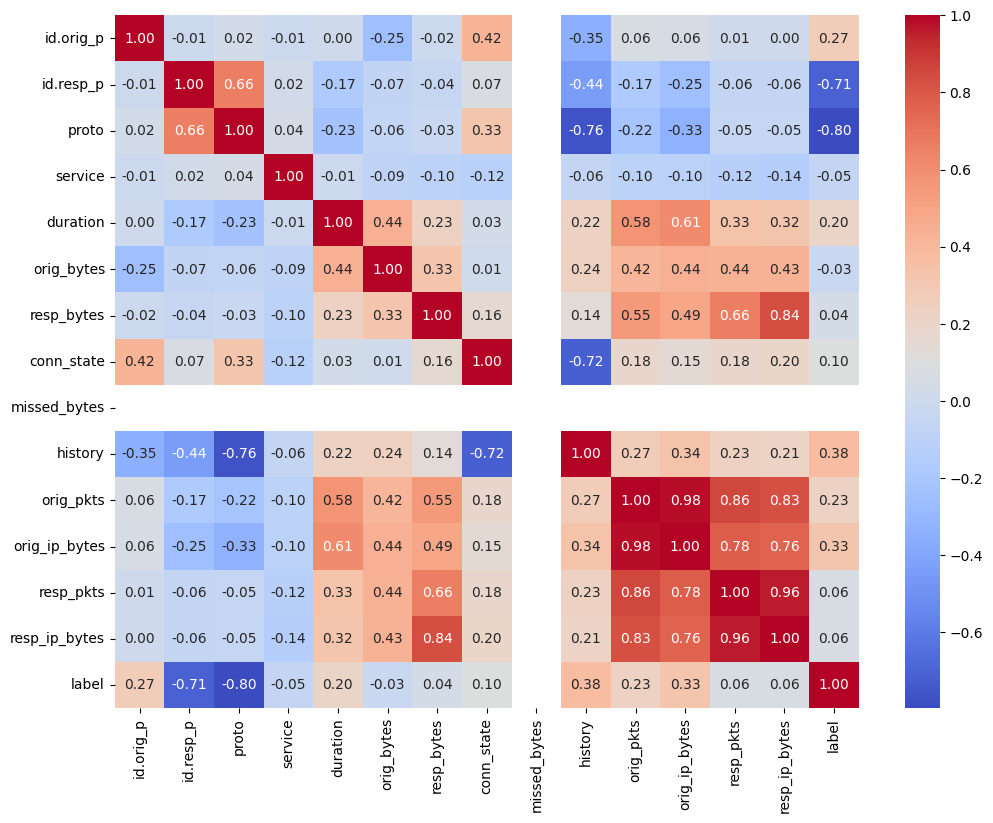

In [19]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

- найбільша кореляція з `label` у `proto` (-0.80) і `id.resp_p` (-0.71)
- `orig_pkts` і `orig_ip_bytes` майже однакові (0.98), так само `resp_pkts` і `resp_ip_bytes`
- `missed_bytes` завжди 0, тому на heatmap порожній

In [20]:
pd.crosstab(df['proto'], df['label'])

label,0,1
proto,,
0,17421,0
1,43695,539439
2,408159,34


Шкідливий трафік - майже повністю TCP, легітимний - в основному UDP.

In [21]:
df[df['label'] == 1]['id.resp_p'].value_counts().head(10)

id.resp_p
23.0      271561
8080.0    135382
2323.0     88184
9527.0     44338
2407.0         8
Name: count, dtype: int64

Mirai сканує порти 23 і 2323 (Telnet), 8080 і 9527 - це видно по портах призначення.

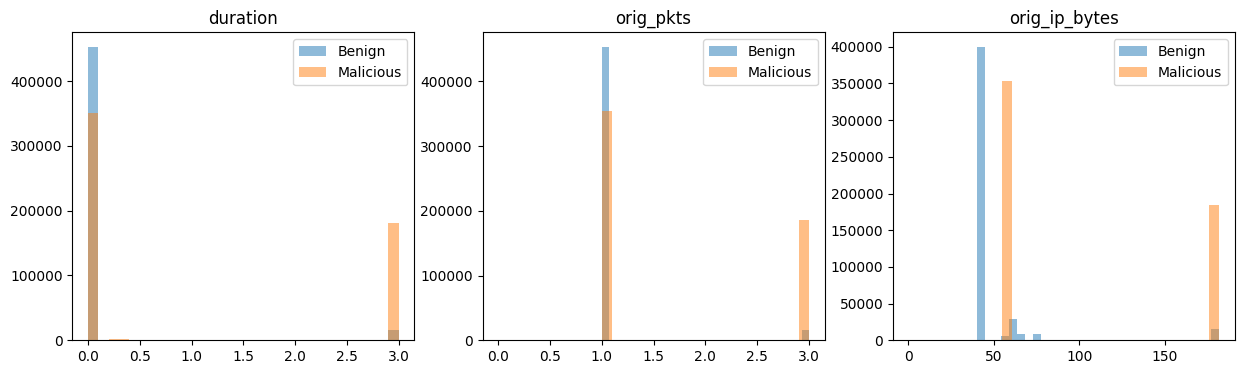

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['duration', 'orig_pkts', 'orig_ip_bytes']):
    ax.hist(df[df['label'] == 0][col].clip(upper=df[col].quantile(0.99)), bins=30, alpha=0.5, label='Benign')
    ax.hist(df[df['label'] == 1][col].clip(upper=df[col].quantile(0.99)), bins=30, alpha=0.5, label='Malicious')
    ax.set_title(col)
    ax.legend()
plt.show()

- у шкідливих з'єднань `duration` або 0, або ~3 секунди (таймаут, коли на SYN ніхто не відповідає)
- `orig_pkts` 1 або 3 - це SYN і дві повторні спроби, тому `orig_ip_bytes` 60 або 180
- у легітимного трафіку майже завжди 1 пакет

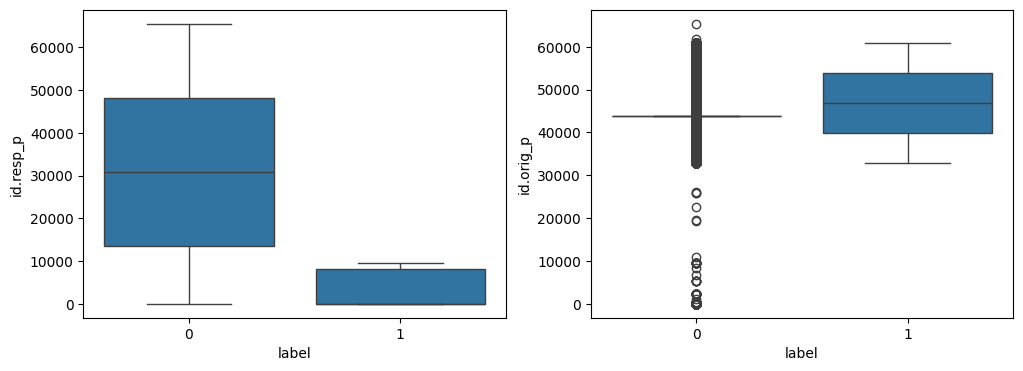

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x='label', y='id.resp_p', data=df, ax=axes[0])
sns.boxplot(x='label', y='id.orig_p', data=df, ax=axes[1])
plt.show()

Порти призначення шкідливого трафіку низькі (до ~10000), у легітимного - по всьому діапазону. Порт джерела у шкідливого трафіку випадковий (32768-61000), у легітимного майже завжди один.

## Train Test Split

In [24]:
X = df.drop(['label'], axis=1)
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [25]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(806998, 14) (806998,)
(201750, 14) (201750,)


## Standardize the Variables

kNN і SVM чутливі до масштабу ознак, тому використовуємо StandardScaler. fit робимо тільки на train.

In [26]:
scaler = StandardScaler()
scaler.fit(X_train)
scaled_X_train = scaler.transform(X_train)
scaled_X_test = scaler.transform(X_test)

## KNN model

In [27]:
knn = KNeighborsClassifier(n_neighbors=5)

In [28]:
knn.fit(scaled_X_train, y_train)

KNeighborsClassifier()

In [29]:
knn_pred = knn.predict(scaled_X_test)

In [30]:
print(confusion_matrix(y_test, knn_pred))
print(classification_report(y_test, knn_pred))
print(accuracy_score(y_test, knn_pred))

[[ 93465    390]
 [     0 107895]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     93855
           1       1.00      1.00      1.00    107895

    accuracy                           1.00    201750
   macro avg       1.00      1.00      1.00    201750
weighted avg       1.00      1.00      1.00    201750

0.9980669144981412


### Choosing a K Value

На всіх даних перебір займає дуже довго (один predict ~5 хв), тому беремо частину вибірки.

In [31]:
X_small, _, y_small, _ = train_test_split(scaled_X_train, y_train, train_size=60000, random_state=42, stratify=y_train)
X_sm_train, X_sm_test, y_sm_train, y_sm_test = train_test_split(X_small, y_small, test_size=0.2, random_state=42)

error_rate = []
for i in range(1, 26, 2):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_sm_train, y_sm_train)
    pred_i = knn.predict(X_sm_test)
    error_rate.append(np.mean(pred_i != y_sm_test))

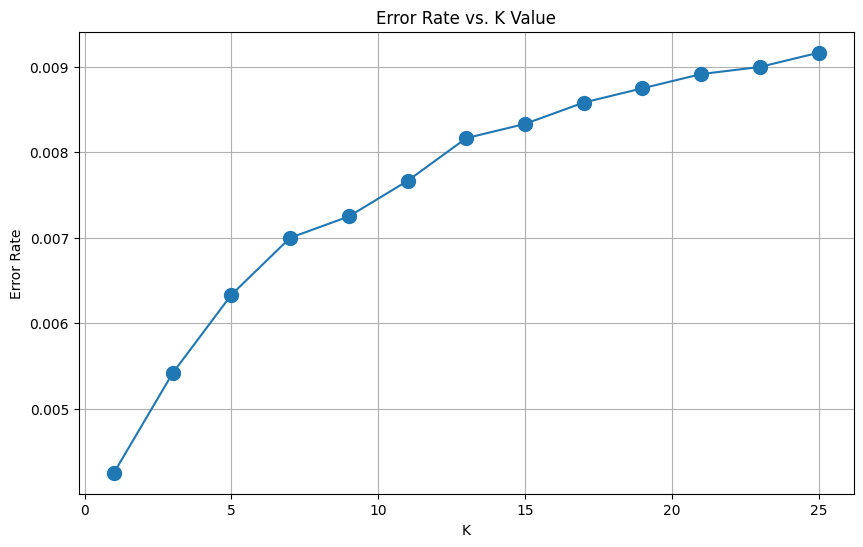

In [32]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 26, 2), error_rate, marker='o', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')
plt.grid()

In [33]:
error_rate

[np.float64(0.00425),
 np.float64(0.005416666666666667),
 np.float64(0.006333333333333333),
 np.float64(0.007),
 np.float64(0.00725),
 np.float64(0.007666666666666666),
 np.float64(0.008166666666666666),
 np.float64(0.008333333333333333),
 np.float64(0.008583333333333333),
 np.float64(0.00875),
 np.float64(0.008916666666666666),
 np.float64(0.009),
 np.float64(0.009166666666666667)]

Помилка найменша при малих k і росте зі збільшенням k. k=1 зазвичай перенавчається, тому беру k=3 - помилка майже така сама, а модель стабільніша.

In [34]:
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(scaled_X_train, y_train)
knn_pred = knn.predict(scaled_X_test)

print(confusion_matrix(y_test, knn_pred))
print(classification_report(y_test, knn_pred))
print(accuracy_score(y_test, knn_pred))

[[ 93528    327]
 [     5 107890]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     93855
           1       1.00      1.00      1.00    107895

    accuracy                           1.00    201750
   macro avg       1.00      1.00      1.00    201750
weighted avg       1.00      1.00      1.00    201750

0.9983543990086741


## Decision Tree

Для дерев масштабування не потрібне, тому беремо X_train без scaler.

In [35]:
dtree = DecisionTreeClassifier(random_state=42)

In [36]:
dtree.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [37]:
dtree_pred = dtree.predict(X_test)

In [38]:
print(confusion_matrix(y_test, dtree_pred))
print(classification_report(y_test, dtree_pred))
print(accuracy_score(y_test, dtree_pred))

[[ 93855      0]
 [     0 107895]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     93855
           1       1.00      1.00      1.00    107895

    accuracy                           1.00    201750
   macro avg       1.00      1.00      1.00    201750
weighted avg       1.00      1.00      1.00    201750

1.0


In [39]:
dtree.get_depth()

10

## SVM model

SVC має складність від O(m^2) до O(m^3), на 800 тис. рядків він навчатиметься дуже довго. Беремо підвибірку 30000.

In [40]:
X_svm, _, y_svm, _ = train_test_split(scaled_X_train, y_train, train_size=30000, random_state=42, stratify=y_train)

In [41]:
svm = SVC(kernel='rbf')

In [42]:
svm.fit(X_svm, y_svm)

SVC()

In [43]:
svm_pred = svm.predict(scaled_X_test)

In [44]:
print(confusion_matrix(y_test, svm_pred))
print(classification_report(y_test, svm_pred))
print(accuracy_score(y_test, svm_pred))

[[ 91696   2159]
 [     8 107887]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     93855
           1       0.98      1.00      0.99    107895

    accuracy                           0.99    201750
   macro avg       0.99      0.99      0.99    201750
weighted avg       0.99      0.99      0.99    201750

0.9892589838909541


### Gridsearch

In [45]:
param_grid = {'C': [0.1, 1, 10, 100], 'gamma': [1, 0.1, 0.01, 0.001], 'kernel': ['rbf']}
grid = GridSearchCV(SVC(), param_grid, cv=3, refit=True, verbose=1)

In [46]:
grid.fit(X_svm, y_svm)

Fitting 3 folds for each of 16 candidates, totalling 48 fits


GridSearchCV(cv=3, estimator=SVC(),
             param_grid={'C': [0.1, 1, 10, 100], 'gamma': [1, 0.1, 0.01, 0.001],
                         'kernel': ['rbf']},
             verbose=1)

In [47]:
grid.best_params_

{'C': 100, 'gamma': 1, 'kernel': 'rbf'}

Найкращі параметри C=100, gamma=1 - обидва на краю сітки. Після GridSearch accuracy виросла з 0.9893 до 0.9913.

In [48]:
grid_pred = grid.predict(scaled_X_test)

In [49]:
print(confusion_matrix(y_test, grid_pred))
print(classification_report(y_test, grid_pred))
print(accuracy_score(y_test, grid_pred))

[[ 92113   1742]
 [    10 107885]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     93855
           1       0.98      1.00      0.99    107895

    accuracy                           0.99    201750
   macro avg       0.99      0.99      0.99    201750
weighted avg       0.99      0.99      0.99    201750

0.9913159851301115


## Random Forest

In [50]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

In [51]:
rf.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [52]:
rf_pred = rf.predict(X_test)

In [53]:
print(confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred))
print(accuracy_score(y_test, rf_pred))

[[ 93844     11]
 [     0 107895]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     93855
           1       1.00      1.00      1.00    107895

    accuracy                           1.00    201750
   macro avg       1.00      1.00      1.00    201750
weighted avg       1.00      1.00      1.00    201750

0.9999454770755886


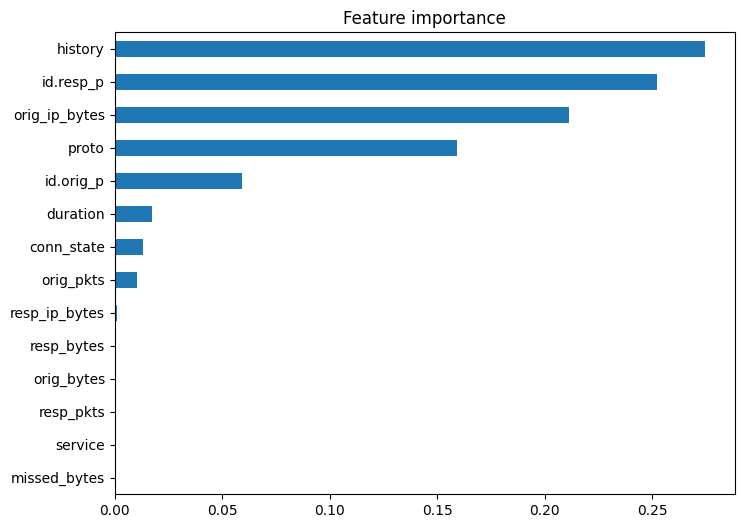

In [54]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importances.plot(kind='barh', figsize=(8, 6))
plt.title('Feature importance')
plt.show()

## AdaBoost

In [55]:
ada = AdaBoostClassifier(n_estimators=100, random_state=42)

In [56]:
ada.fit(X_train, y_train)

AdaBoostClassifier(n_estimators=100, random_state=42)

In [57]:
ada_pred = ada.predict(X_test)

In [58]:
print(confusion_matrix(y_test, ada_pred))
print(classification_report(y_test, ada_pred))
print(accuracy_score(y_test, ada_pred))

[[ 92578   1277]
 [     8 107887]]
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     93855
           1       0.99      1.00      0.99    107895

    accuracy                           0.99    201750
   macro avg       0.99      0.99      0.99    201750
weighted avg       0.99      0.99      0.99    201750

0.99363073110285


## Порівняння моделей

In [59]:
results = pd.DataFrame({
    'model': ['kNN (k=3)', 'Decision Tree', 'SVM (GridSearch)', 'Random Forest', 'AdaBoost'],
    'accuracy': [accuracy_score(y_test, knn_pred), accuracy_score(y_test, dtree_pred),
                 accuracy_score(y_test, grid_pred), accuracy_score(y_test, rf_pred),
                 accuracy_score(y_test, ada_pred)]
})
results.sort_values('accuracy', ascending=False)

,model,accuracy
1,Decision Tree,1.000000
3,Random Forest,0.999945
0,kNN (k=3),0.998354
4,AdaBoost,0.993631
2,SVM (GridSearch),0.991316


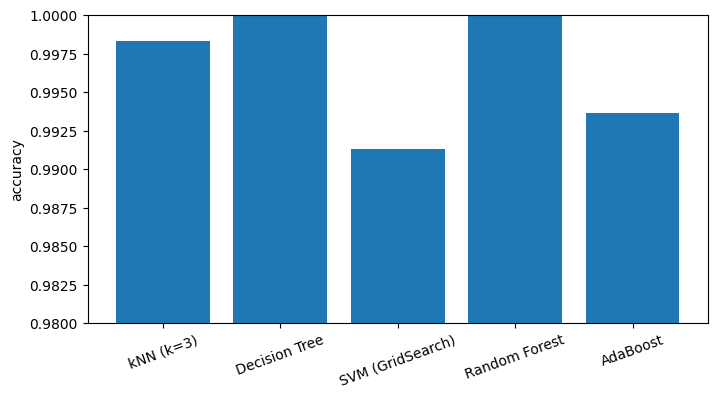

In [60]:
plt.figure(figsize=(8, 4))
plt.bar(results['model'], results['accuracy'])
plt.ylim(0.98, 1.0)
plt.ylabel('accuracy')
plt.xticks(rotation=20)
plt.show()

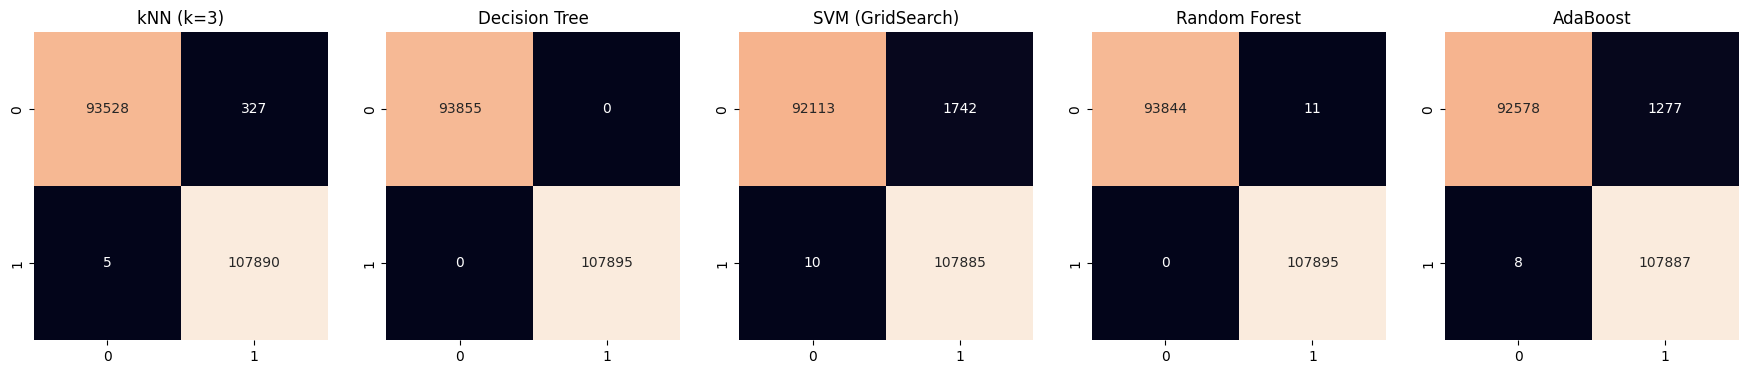

In [61]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
preds = [knn_pred, dtree_pred, grid_pred, rf_pred, ada_pred]
for ax, name, p in zip(axes, results['model'], preds):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt='d', ax=ax, cbar=False)
    ax.set_title(name)
plt.show()

### Перевірка дублікатів

Точність майже 100%, тому перевіряю, чи не через те, що однакові рядки потрапили і в train, і в test.

In [62]:
df.duplicated().sum() / len(df)

np.float64(0.6385906093494114)

In [63]:
df_unique = df.drop_duplicates()
X_u = df_unique.drop(['label'], axis=1)
y_u = df_unique['label']
Xu_train, Xu_test, yu_train, yu_test = train_test_split(X_u, y_u, test_size=0.2, random_state=42, stratify=y_u)

dtree_u = DecisionTreeClassifier(random_state=42)
dtree_u.fit(Xu_train, yu_train)
print(accuracy_score(yu_test, dtree_u.predict(Xu_test)))

0.9999862854008091


Дублікатів ~64%, але на унікальних рядках точність така сама. Тобто справа не в дублікатах - класи в цьому датасеті просто дуже добре розділяються.

## Висновки

Усі п'ять моделей показали accuracy вище 0.98. Найкращий результат у Decision Tree і Random Forest (майже 1.0), далі kNN, AdaBoost і SVM.

Дерева працюють найкраще, тому що шкідливий трафік тут відрізняється простими правилами: протокол TCP, порт 23/2323/8080, у history тільки SYN, 1 або 3 пакети. Дерево якраз будує такі правила. Важливість ознак у Random Forest це підтверджує - найважливіші `history`, `id.resp_p`, `orig_ip_bytes`, `proto`.

kNN теж дає високу точність, але predict на 200 тис. рядків займає кілька хвилин, для системи виявлення вторгнень це занадто повільно. SVM навчався тільки на 30 тис. рядків і має найбільше хибних спрацювань на легітимному трафіку. AdaBoost трохи гірший за дерево, бо використовує слабкі класифікатори (пні глибини 1).

Обмеження: весь датасет - це один захват з одного зараженого пристрою, тому модель вивчила саме цей варіант Mirai і саме цю мережу. На іншому трафіку точність, скоріше за все, буде нижча, для перевірки треба брати інші захвати з IoT-23.